# Neural Network from Scratch

Implement a general feedforward neural network using NumPy, including forward propagation, loss calculation, backpropagation, and gradient descent.

## Mathematical Notation

- N: Number of samples
- n_l: Number of neurons in layer l
- X: Input matrix
- W[l]: Weight matrix of layer l
- b[l]: Bias vector of layer l
- Z[l]: Output before activation
- A[l]: Output after activation

## Forward Propagation

For each layer, the network performs a linear transformation followed by an activation function.

Z[l] = A[l-1] @ W[l] + b[l]

A[l] = g(Z[l])

The input to the first layer is A[0] = X.

Here, @ denotes matrix multiplication and g denotes the activation function.

## Matrix Dimensions

Let:
- N = number of samples
- n0 = number of input features
- nl = number of neurons in layer l

For layer l:

- A[l-1]: (N, n[l-1])
- W[l]: (n[l-1], n[l])
- b[l]: (1, n[l])
- Z[l]: (N, n[l])
- A[l]: (N, n[l])

The forward operation is:

Z[l] = A[l-1] @ W[l] + b[l]

A[l] = g(Z[l])

The bias is broadcast across all N samples.

In [2]:
import numpy as np

def initialize_parameters(layer_sizes):
    parameters = {}

    for l in range(1, len(layer_sizes)):
        n_in = layer_sizes[l - 1]
        n_out = layer_sizes[l]

        parameters[f"W{l}"] = (
            np.random.randn(n_in, n_out) * np.sqrt(2 / n_in)
        )
        parameters[f"b{l}"] = np.zeros((1, n_out))

    return parameters

## Activation Functions

ReLU is used in hidden layers:

g(z) = max(0, z)

Sigmoid is used in the output layer for binary classification:

g(z) = 1 / (1 + exp(-z))

In [3]:
def relu(Z):
    return np.maximum(0, Z)


def sigmoid(Z):
    Z = np.clip(Z, -500, 500)
    return 1 / (1 + np.exp(-Z))

## Forward Propagation

Forward propagation calculates the network's output by passing input data through each layer.

For each layer l:

Z[l] = A[l-1] @ W[l] + b[l]

A[l] = g(Z[l])

The first layer receives the input X, so A[0] = X.

The final activation gives the network's prediction.

In [4]:
def forward_propagation(X, parameters):
    activations = {"A0": X}
    L = len(parameters) // 2

    for l in range(1, L + 1):
        A_prev = activations[f"A{l - 1}"]

        W = parameters[f"W{l}"]
        b = parameters[f"b{l}"]

        Z = A_prev @ W + b

        if l == L:
            A = sigmoid(Z)
        else:
            A = relu(Z)

        activations[f"Z{l}"] = Z
        activations[f"A{l}"] = A

    return activations[f"A{L}"], activations

## Loss Function

Binary cross-entropy measures the difference between the true labels and predicted probabilities.

L = -(1/N) * sum(y * log(y_hat) + (1-y) * log(1-y_hat))

Where:
- N: Number of samples
- y: True label (0 or 1)
- y_hat: Predicted probability

The objective is to minimize the loss during training.

In [5]:
def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon) # prevents log(0)

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

## Backpropagation

Backpropagation calculates the gradients of the loss with respect to each weight and bias using the chain rule.

These gradients indicate how the parameters affect the loss and are used to update them during gradient descent.

For each parameter θ:

dL/dθ = gradient of the loss with respect to θ

### Output Layer Gradients

For the last layer, backpropagation starts by calculating the gradient with respect to Z:

dZ[L] = (A[L] - Y) / N

Then:

dW[L] = A[L-1].T @ dZ[L]

db[L] = sum(dZ[L])

### Hidden Layer Gradients

The gradient is propagated backward to the previous layer:

dA[l-1] = dZ[l] @ W[l].T

For a hidden layer using ReLU:

dZ[l-1] = dA[l-1] * ReLU'(Z[l-1])

Then:

dW[l-1] = A[l-2].T @ dZ[l-1]

db[l-1] = sum(dZ[l-1])

In [7]:
def relu_derivative(Z):
   return (Z > 0).astype(float)

In [8]:
def backward_propagation(y_true, y_pred, parameters, activations):
    gradients = {}

    L = len(parameters) // 2

    # Output layer
    dZ = (y_pred - y_true) / y_true.shape[0]

    for l in range(L, 0, -1):
        A_prev = activations[f"A{l - 1}"]

        gradients[f"dW{l}"] = A_prev.T @ dZ
        gradients[f"db{l}"] = np.sum(dZ, axis=0, keepdims=True)

        if l > 1:
            W = parameters[f"W{l}"]

            dA_prev = dZ @ W.T
            Z_prev = activations[f"Z{l - 1}"]

            dZ = dA_prev * relu_derivative(Z_prev)

    return gradients

## Gradient Descent

The parameters are updated using their gradients:

W[l] = W[l] - learning_rate * dW[l]

b[l] = b[l] - learning_rate * db[l]

In [9]:
def update_parameters(parameters, gradients, learning_rate):
    L = len(parameters) // 2

    for l in range(1, L + 1):
        parameters[f"W{l}"] -= learning_rate * gradients[f"dW{l}"]
        parameters[f"b{l}"] -= learning_rate * gradients[f"db{l}"]

    return parameters

In [10]:
def train(X, y, layer_sizes, epochs, learning_rate):
    parameters = initialize_parameters(layer_sizes)
    losses = []

    for epoch in range(epochs):
        y_pred, activations = forward_propagation(X, parameters)

        loss = binary_cross_entropy(y, y_pred)
        losses.append(loss)

        gradients = backward_propagation(
            y,
            y_pred,
            parameters,
            activations
        )

        parameters = update_parameters(
            parameters,
            gradients,
            learning_rate
        )

    return parameters, losses

## Training on a Simple Dataset

Before using a real dataset, we test the neural network on a simple binary classification dataset to verify that the implementation works correctly.

In [12]:
from sklearn.datasets import make_moons

X, y = make_moons(
    n_samples=500,
    noise=0.2,
    random_state=42
)

y = y.reshape(-1, 1)

In [13]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (500, 2)
y shape: (500, 1)


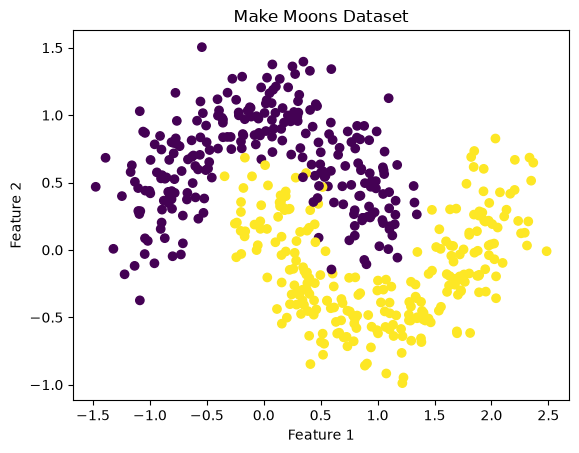

In [14]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=y.ravel())

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Make Moons Dataset")

plt.show()

In [23]:
layer_sizes = [2, 8, 4, 1]

parameters, losses = train(
    X,
    y,
    layer_sizes=layer_sizes,
    epochs=1000,
    learning_rate=0.5
)

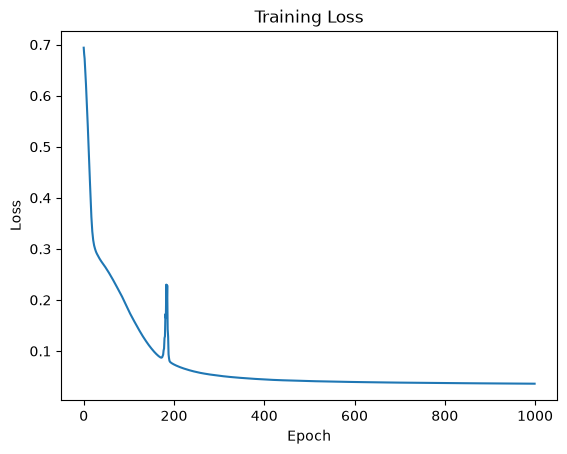

In [24]:
plt.plot(losses)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()

In [25]:
y_pred, _ = forward_propagation(X, parameters)

predictions = (y_pred >= 0.5).astype(int)

accuracy = np.mean(predictions == y)

print("Accuracy:", accuracy)

Accuracy: 0.984


In [26]:
print("Final Loss:", losses[-1])

Final Loss: 0.036046779004004874


In [28]:
def plot_decision_boundary(X, y, parameters):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    probabilities, _ = forward_propagation(grid, parameters)

    predictions = (probabilities >= 0.5).astype(int)
    predictions = predictions.reshape(xx.shape)

    plt.contourf(xx, yy, predictions, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y.ravel())

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Neural Network Decision Boundary")

    plt.show()

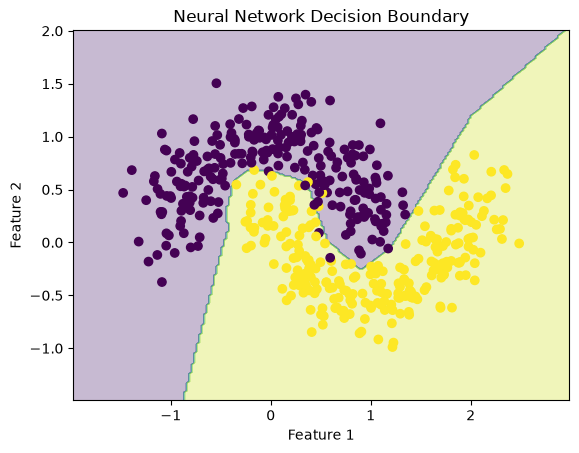

In [29]:
plot_decision_boundary(X, y, parameters)

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [32]:
y_test_pred, _ = forward_propagation(X_test, parameters)

test_predictions = (y_test_pred >= 0.5).astype(int)

test_accuracy = np.mean(test_predictions == y_test)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.99


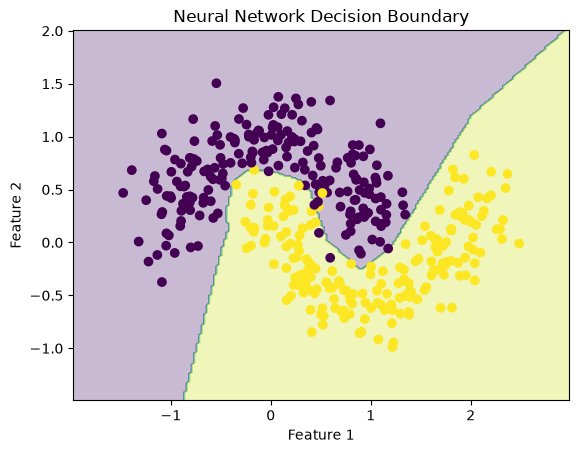

In [33]:
plot_decision_boundary(X_train, y_train, parameters)

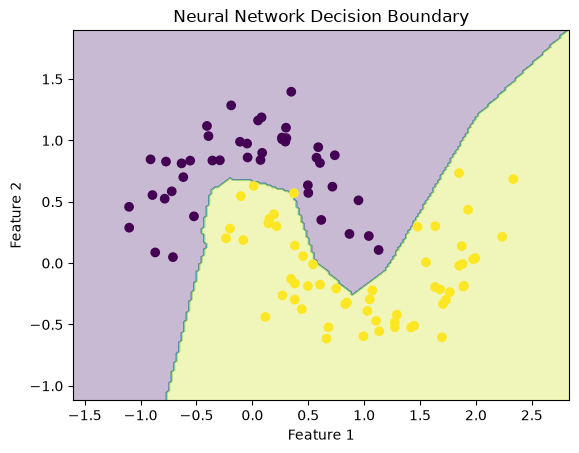

In [34]:
plot_decision_boundary(X_test, y_test, parameters)

## Results

The neural network was trained on the Make Moons dataset using:

- Architecture: 2 → 8 → 4 → 1
- Hidden activation: ReLU
- Output activation: Sigmoid
- Loss: Binary Cross-Entropy
- Optimizer: Batch Gradient Descent
- Learning rate: 0.5
- Epochs: 1000

The model achieved approximately:

- Training Accuracy: 98.4%
- Test Accuracy: 99%
- Final Training Loss: 0.036

## Conclusion

In this project, I implemented a feedforward neural network from scratch using NumPy. The implementation included forward propagation, binary cross-entropy loss, backpropagation, and gradient descent.

The model successfully learned the nonlinear pattern in the Make Moons dataset and achieved high accuracy on unseen test data.